In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
# --- 1. CARGA DE DATOS ---
# Sustituye 'tu_archivo.xlsx' por el nombre real de tu excel
file_path = 'KNN_DATA.xlsx' 
df = pd.read_excel(file_path)

In [3]:
# --- 2. CONFIGURACIÓN DEL MODELO ---
# Definimos las columnas exactas que me has dicho
features = ['FAC2', 'FAC3', 'FAC4', 'FAC5']
target = 'TAMAÑO'     # 1,00 o 0,00
ticker_col = 'NOMBRE' # Donde están los tickers (AAPL, MSFT...)

X = df[features]
y = df[target]

# Dividimos 70% entrenamiento y 30% test (random_state=42 para que sea replicable siempre igual)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

# Creamos el modelo con k=11
k = 11
knn = KNeighborsClassifier(n_neighbors=k)
knn.fit(X_train, y_train)

,n_neighbors,11
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [4]:

# --- 3. RESULTADOS GENERALES (Réplica de SPSS) ---
print("--- RENDIMIENTO DEL MODELO (K=11) ---")
y_pred = knn.predict(X_test)

print("\nMatriz de Confusión:")
print(confusion_matrix(y_test, y_pred))

print("\nInforme de Clasificación:")
print(classification_report(y_test, y_pred))

--- RENDIMIENTO DEL MODELO (K=11) ---

Matriz de Confusión:
[[61 15]
 [30 45]]

Informe de Clasificación:
              precision    recall  f1-score   support

           0       0.67      0.80      0.73        76
           1       0.75      0.60      0.67        75

    accuracy                           0.70       151
   macro avg       0.71      0.70      0.70       151
weighted avg       0.71      0.70      0.70       151



In [7]:
# --- 4. ANÁLISIS ESTRATÉGICO: LAS 'BIG 7' ---
# Este es el bloque clave para tu TFG. Vamos a ver qué "opinan" los vecinos.

# Lista de tickers a auditar (asegúrate de que están escritos igual que en tu Excel)
big7_tickers = ['AAPL', 'MSFT', 'GOOG', 'AMZN', 'NVDA', 'TSLA', 'META'] 
# Nota: A veces Google es GOOG o GOOGL, revisa tu excel.

print("\n" + "="*50)
print(f"ANÁLISIS DE VECINOS PARA LAS {len(big7_tickers)} MAGNÍFICAS")
print("="*50)

# Filtramos los datos de estas empresas (estén en train o en test, nos da igual)
big7_data = df[df[ticker_col].isin(big7_tickers)].copy()

if not big7_data.empty:
    # Obtenemos sus variables para calcular distancias
    X_big7 = big7_data[features]
    
    # 1. ¿Qué predice el modelo para ellas?
    predicciones_big7 = knn.predict(X_big7)
    
    # 2. ¿Quiénes son sus vecinos? (Indices dentro de X_train)
    distancias, indices_vecinos = knn.kneighbors(X_big7)
    
    resultados = []
    
    # Recorremos cada empresa encontrada
    for i, (idx_original, row) in enumerate(big7_data.iterrows()):
        nombre_empresa = row[ticker_col]
        clase_real = "Grande" if row[target] == 1 else "Pequeña"
        clase_predicha = "Grande" if predicciones_big7[i] == 1 else "Pequeña"
        
        # Buscamos la votación de sus 11 vecinos en el set de entrenamiento
        # indices_vecinos[i] nos da la posición numérica en X_train
        vecinos_reales_y = y_train.iloc[indices_vecinos[i]]
        
        # Contamos cuántos vecinos son "Clase 1" (Grandes)
        votos_positivos = (vecinos_reales_y == 1).sum()
        porcentaje_consenso = (votos_positivos / k) * 100
        
        resultados.append({
            'Empresa': nombre_empresa,
            'Real': clase_real,
            'Predicción': clase_predicha,
            'Consenso Vecinos': f"{votos_positivos}/{k} ({porcentaje_consenso:.1f}%)"
        })
    
    # Mostramos la tabla bonita
    df_resultados = pd.DataFrame(resultados)
    print(df_resultados.to_markdown(index=False)) # Requiere 'tabulate', si falla usa print(df_resultados)
    
else:
    print("⚠️ No se encontraron las empresas especificadas en la columna NOMBRE.")
    print("Por favor, verifica que los tickers (AAPL, MSFT...) coinciden con tu Excel.")


ANÁLISIS DE VECINOS PARA LAS 7 MAGNÍFICAS
| Empresa   | Real   | Predicción   | Consenso Vecinos   |
|:----------|:-------|:-------------|:-------------------|
| GOOG      | Grande | Grande       | 9/11 (81.8%)       |
| AMZN      | Grande | Grande       | 10/11 (90.9%)      |
| AAPL      | Grande | Grande       | 7/11 (63.6%)       |
| META      | Grande | Grande       | 9/11 (81.8%)       |
| MSFT      | Grande | Grande       | 7/11 (63.6%)       |
| NVDA      | Grande | Grande       | 10/11 (90.9%)      |
| TSLA      | Grande | Grande       | 7/11 (63.6%)       |


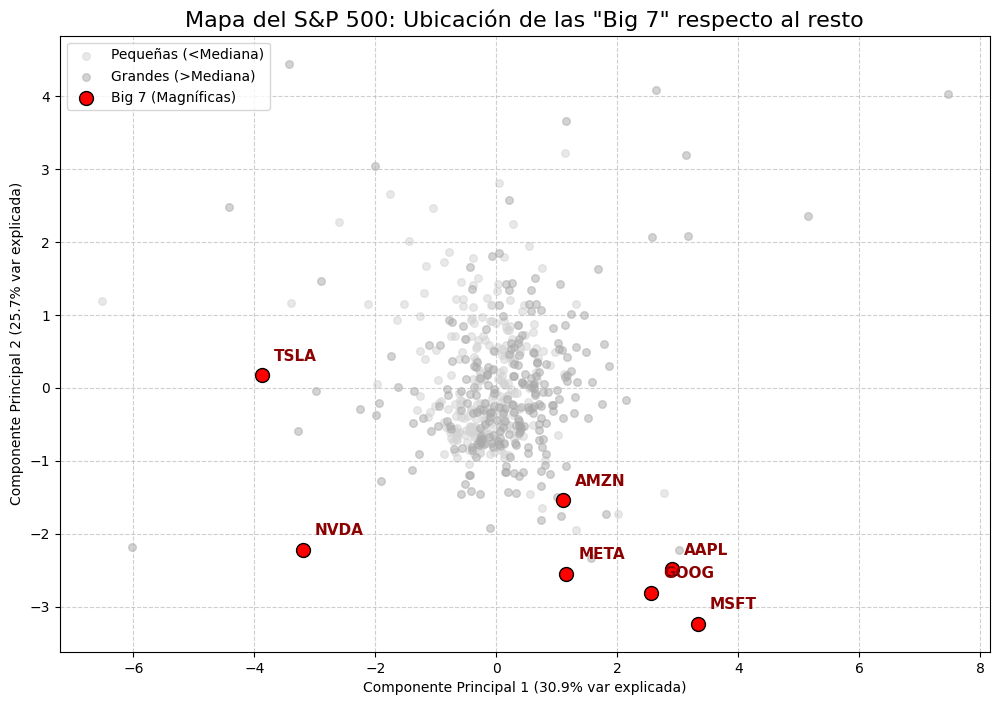

Gráfico generado y guardado como 'grafico_pca_big7.png'


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# 1. Preparamos los datos para el gráfico
# Usamos TODAS las empresas (X) para que se vea el contexto global
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X) # Aplastamos las 4 dimensiones a 2

# Creamos un DataFrame temporal para facilitar el ploteo
df_plot = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_plot['Ticker'] = df[ticker_col].values
df_plot['Tamaño'] = y.values # 1=Grande, 0=Pequeña
df_plot['Es_Big7'] = df_plot['Ticker'].isin(big7_tickers)

# 2. Configuración del gráfico
plt.figure(figsize=(12, 8))

# Capa 1: El fondo (Resto de empresas)
# Pequeñas
subset_0 = df_plot[(df_plot['Tamaño'] == 0) & (~df_plot['Es_Big7'])]
plt.scatter(subset_0['PC1'], subset_0['PC2'], c='lightgray', label='Pequeñas (<Mediana)', alpha=0.5, s=30)

# Grandes
subset_1 = df_plot[(df_plot['Tamaño'] == 1) & (~df_plot['Es_Big7'])]
plt.scatter(subset_1['PC1'], subset_1['PC2'], c='darkgray', label='Grandes (>Mediana)', alpha=0.5, s=30)

# Capa 2: Las Big 7 (Destacadas)
subset_big7 = df_plot[df_plot['Es_Big7']]
plt.scatter(subset_big7['PC1'], subset_big7['PC2'], c='red', label='Big 7 (Magníficas)', s=100, edgecolors='black')

# 3. Ponemos las etiquetas de los nombres
for i, row in subset_big7.iterrows():
    plt.text(row['PC1']+0.2, row['PC2']+0.2, row['Ticker'], fontsize=11, fontweight='bold', color='darkred')

# Detalles finales
plt.title('Mapa del S&P 500: Ubicación de las "Big 7" respecto al resto', fontsize=16)
plt.xlabel(f'Componente Principal 1 ({pca.explained_variance_ratio_[0]:.1%} var explicada)')
plt.ylabel(f'Componente Principal 2 ({pca.explained_variance_ratio_[1]:.1%} var explicada)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Guardar y mostrar
plt.savefig('grafico_pca_big7.png', dpi=300)
plt.show()
print("Gráfico generado y guardado como 'grafico_pca_big7.png'")

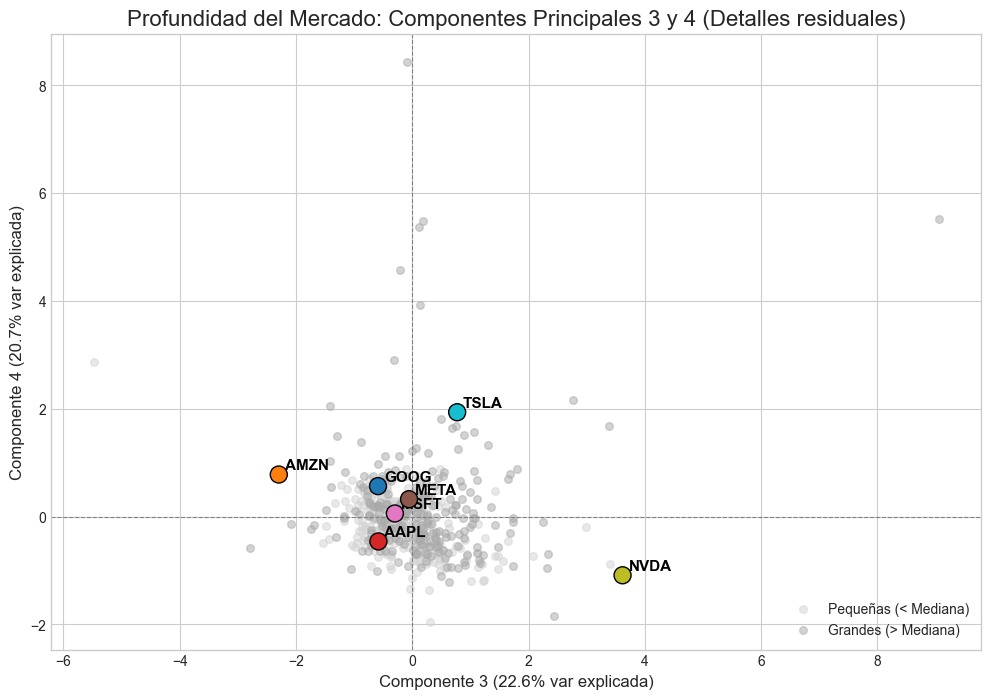

Gráfico generado: mapa_knn_big7_pc3_pc4.png


In [11]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import pandas as pd # Aseguramos que pandas esté importado

# --- GRÁFICO PCA: COMPONENTES 3 Y 4 (La "Letra Pequeña") ---

# 1. Calculamos las 4 componentes (para poder coger las últimas)
pca = PCA(n_components=4) 
X_pca = pca.fit_transform(X)

# Creamos el DataFrame para el gráfico usando las columnas de índice 2 y 3
# (Recordatorio: Python cuenta 0, 1, 2, 3 -> La 2 y 3 son la 3ª y 4ª)
df_plot = pd.DataFrame(X_pca, columns=['PC1', 'PC2', 'PC3', 'PC4'])
df_plot['Es_Big7'] = df[ticker_col].isin(big7_tickers)
df_plot['Clase_Real'] = y.values 

# 2. Configuración del gráfico
plt.figure(figsize=(12, 8))
plt.style.use('seaborn-v0_8-whitegrid')

# Varianzas explicadas (para ponerlo en los ejes)
var_exp = pca.explained_variance_ratio_

# A. Fondo (Resto del mercado)
# Pequeñas
subset_peques = df_plot[(df_plot['Clase_Real'] == 0) & (~df_plot['Es_Big7'])]
plt.scatter(subset_peques['PC3'], subset_peques['PC4'], 
            c='lightgray', alpha=0.5, label='Pequeñas (< Mediana)', s=30)

# Grandes
subset_grandes = df_plot[(df_plot['Clase_Real'] == 1) & (~df_plot['Es_Big7'])]
plt.scatter(subset_grandes['PC3'], subset_grandes['PC4'], 
            c='darkgray', alpha=0.5, label='Grandes (> Mediana)', s=30)

# B. Las Big 7 (Protagonistas)
subset_big7 = df_plot[df_plot['Es_Big7']]
plt.scatter(subset_big7['PC3'], subset_big7['PC4'], 
            c=range(len(subset_big7)), cmap='tab10', s=150, edgecolors='black', zorder=10)

# C. Etiquetas
for i, row in df[df[ticker_col].isin(big7_tickers)].iterrows():
    # Busamos índice correspondiente
    idx_plot = df.index.get_loc(i)
    # Cogemos coordenadas de las columnas 2 (PC3) y 3 (PC4)
    x_coord = X_pca[idx_plot, 2] 
    y_coord = X_pca[idx_plot, 3]
    
    plt.text(x_coord + 0.1, y_coord + 0.1, row[ticker_col], 
             fontsize=11, fontweight='bold', color='black')

# Decoración
plt.title('Profundidad del Mercado: Componentes Principales 3 y 4 (Detalles residuales)', fontsize=16)
plt.xlabel(f'Componente 3 ({var_exp[2]:.1%} var explicada)', fontsize=12)
plt.ylabel(f'Componente 4 ({var_exp[3]:.1%} var explicada)', fontsize=12)
plt.legend(loc='lower right')
plt.axhline(0, color='grey', linewidth=0.8, linestyle='--')
plt.axvline(0, color='grey', linewidth=0.8, linestyle='--')

plt.savefig('mapa_knn_big7_pc3_pc4.png', dpi=300)
plt.show()

print("Gráfico generado: mapa_knn_big7_pc3_pc4.png")